In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df=pd.read_csv("/content/drive/MyDrive/dataset/student_exam_scores.csv")
print(df)

    student_id  hours_studied  sleep_hours  attendance_percent  \
0         S001            8.0          8.8                72.1   
1         S002            1.3          8.6                60.7   
2         S003            4.0          8.2                73.7   
3         S004            3.5          4.8                95.1   
4         S005            9.1          6.4                89.8   
..         ...            ...          ...                 ...   
195       S196           10.5          5.4                94.0   
196       S197            7.1          6.1                85.1   
197       S198            1.6          6.9                63.8   
198       S199           12.0          7.3                50.5   
199       S200           10.2          6.3                97.4   

     previous_scores  exam_score  
0                 45        30.2  
1                 55        25.0  
2                 86        35.8  
3                 66        34.0  
4                 71        40.3

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df.head()

,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


In [ ]:
print(df.columns)

Index(['student_id', 'hours_studied', 'sleep_hours', 'attendance_percent',
       'previous_scores', 'exam_score'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          200 non-null    object 
 1   hours_studied       200 non-null    float64
 2   sleep_hours         200 non-null    float64
 3   attendance_percent  200 non-null    float64
 4   previous_scores     200 non-null    int64  
 5   exam_score          200 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 9.5+ KB


In [ ]:
print(df.isnull().sum())

student_id            0
hours_studied         0
sleep_hours           0
attendance_percent    0
previous_scores       0
exam_score            0
dtype: int64


In [ ]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [ ]:
df.describe()

,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,6.325500,6.622000,74.830000,66.800000,33.955000
std,3.227317,1.497138,14.249905,15.663869,6.789548
min,1.000000,4.000000,50.300000,40.000000,17.100000
25%,3.500000,5.300000,62.200000,54.000000,29.500000
50%,6.150000,6.700000,75.250000,67.500000,34.050000
75%,9.000000,8.025000,87.425000,80.000000,38.750000
max,12.000000,9.000000,100.000000,95.000000,51.300000


In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df["hours_studied"], df["exam_score"])

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")

plt.title("Study Hours vs Exam Score")

plt.show()

NameError: name 'df' is not defined

<Figure size 800x500 with 0 Axes>

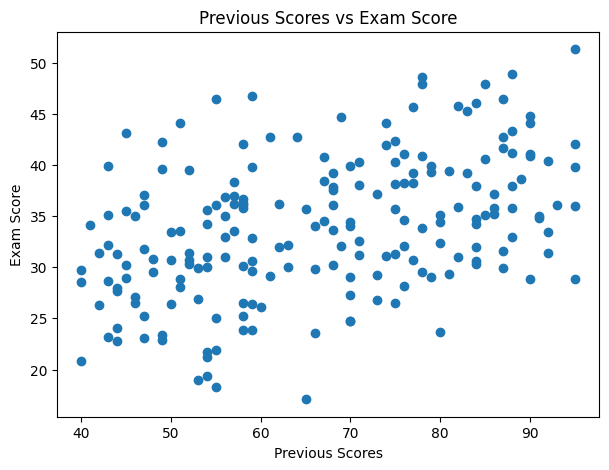

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(df['previous_scores'], df['exam_score'])

plt.xlabel("Previous Scores")
plt.ylabel("Exam Score")

plt.title("Previous Scores vs Exam Score")

plt.show()

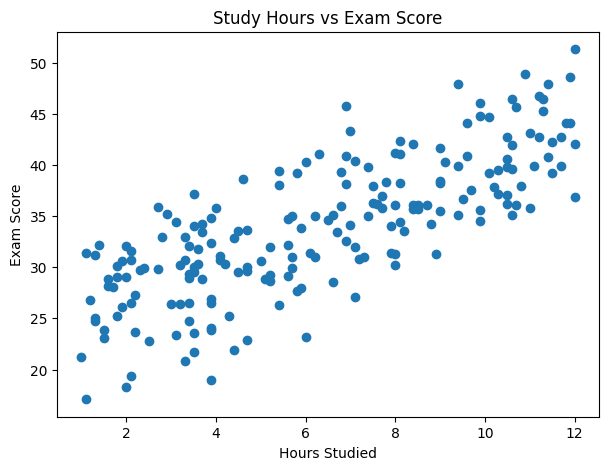

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(df['hours_studied'], df['exam_score'])

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.show()

In [ ]:
X = df[['hours_studied',
        'sleep_hours',
        'attendance_percent',
        'previous_scores']]

y = df['exam_score']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 4)
Testing data: (40, 4)


In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print(y_pred)

[28.88607164 29.68042066 35.31195586 31.18044826 39.44894287 41.69158322
 23.96918347 45.72250896 41.6529321  27.47615681 26.09033959 44.45348162
 27.22577144 29.33836752 36.53825172 34.75877399 31.5395367  28.52996777
 40.3792585  29.84951368 21.85245583 24.08822626 27.61839558 27.93331998
 35.96012145 43.8081039  34.91507705 28.592239   37.57486402 43.9712545
 27.7683444  37.33910217 37.03824477 28.28799615 42.6421297  21.64648068
 38.42517152 36.15049022 44.91531908 35.47066788]


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 2.310858235895833
MSE: 7.761782668623075
RMSE: 2.785997607433121
R2 Score: 0.8537447137159516


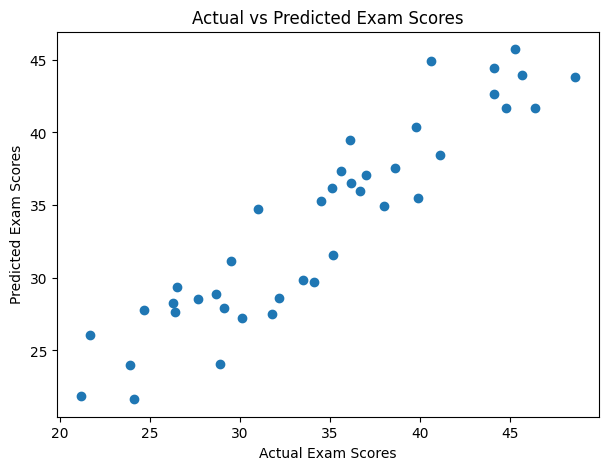

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")

plt.title("Actual vs Predicted Exam Scores")

plt.show()

In [ ]:
result = pd.DataFrame({
    'Actual Score': y_test.values,
    'Predicted Score': y_pred
})

result.head(10)

,Actual Score,Predicted Score
0,28.7,28.886072
1,34.1,29.680421
2,34.5,35.311956
3,29.5,31.180448
4,36.1,39.448943
5,46.4,41.691583
6,23.9,23.969183
7,45.3,45.722509
8,44.8,41.652932
9,31.8,27.476157


In [ ]:
new_student = pd.DataFrame({
    'hours_studied': [8],
    'sleep_hours': [7],
    'attendance_percent': [90],
    'previous_scores': [80]
})

predicted_score = model.predict(new_student)

print("Predicted Exam Score:", predicted_score[0])

Predicted Exam Score: 40.82699659607464


In [ ]:
print("Intercept:", model.intercept_)

print("Coefficients:", model.coef_)

Intercept: -2.204963905836877
Coefficients: [1.54934126 0.88415643 0.10894946 0.18303355]
